# Chapter 9. 시계열 분석

### 1. MarketWatch 자료 받고 확인

- https://www.marketwatch.com/investing/index/spx/download-data

MarketWatch는 주식, 금융, 경제 뉴스와 데이터를 제공하는 금융 미디어 웹사이트다. 이 사이트는 투자자, 트레이더, 재정 전문가들을 대상으로 최신 시장 동향, 금융 뉴스, 주식 및 상품 가격 정보, 금융 지표, 경제 전망 등을 제공한다.

주요 특징은 다음과 같다:

1. **시장 데이터**: 실시간 주식, 채권, 상품, 외환 시장의 데이터를 제공하며, 개별 종목의 상세 정보(차트, 재무제표, 기업 분석 등)를 확인할 수 있다.

2. **뉴스**: 경제 및 금융과 관련된 최신 뉴스를 다루며, 기업 실적 발표, 경제 정책 변화, 글로벌 금융 시장 동향 등을 분석한다.

3. **도구 및 리소스**: 투자 및 금융 계획을 돕기 위한 다양한 도구(포트폴리오 관리, 주식 스크리너 등)를 제공해 재정 계획을 세우는 데 필요한 정보를 쉽게 접근할 수 있다.

4. **칼럼 및 분석**: 유명 경제학자와 금융 전문가들의 칼럼과 분석 기사를 통해 독자들은 깊이 있는 금융 및 경제 지식을 얻을 수 있다.

5. **커뮤니티 및 의견 공유**: 투자자들 간의 의견 교환과 토론이 가능한 게시판과 댓글 시스템도 갖추고 있어, 다양한 시각을 접할 수 있다.

MarketWatch는 특히 미국 및 글로벌 주식 시장에 대한 정보를 신속하고 정확하게 제공하여, 투자 결정을 내리는 데 필요한 자료를 제공한다.

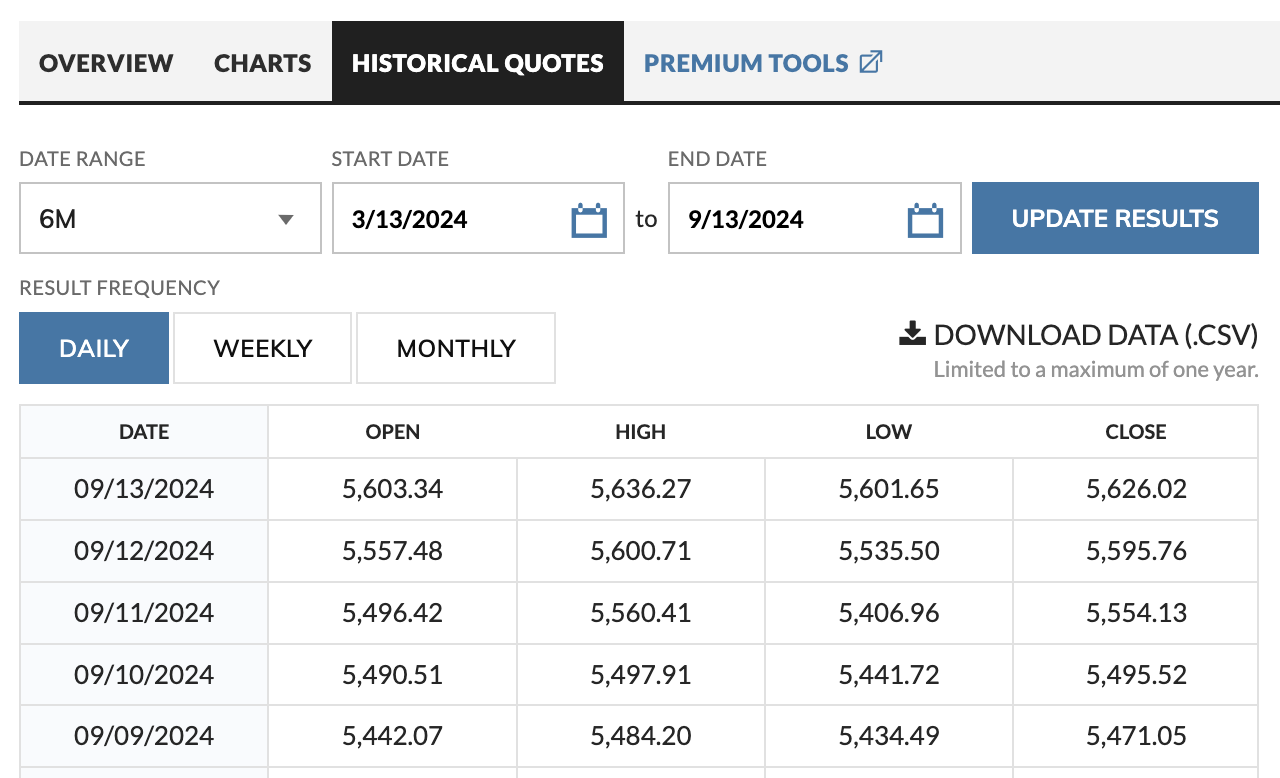

In [1]:
import pandas as pd
df = pd.read_csv('./data/INDEX_US.csv')
df.head()

,Date,Open,High,Low,Close
0,09/13/2024,"5,603.34","5,636.27","5,601.65","5,626.02"
1,09/12/2024,"5,557.48","5,600.71","5,535.50","5,595.76"
2,09/11/2024,"5,496.42","5,560.41","5,406.96","5,554.13"
3,09/10/2024,"5,490.51","5,497.91","5,441.72","5,495.52"
4,09/09/2024,"5,442.07","5,484.20","5,434.49","5,471.05"


In [2]:
df.describe()

,Date,Open,High,Low,Close
count,128,128,128,128,128
unique,128,128,128,127,128
top,09/13/2024,"5,603.34","5,636.27","5,560.95","5,626.02"
freq,1,1,1,2,1


In [3]:
df.dtypes

Date     str
Open     str
High     str
Low      str
Close    str
dtype: object

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Date    128 non-null    str  
 1   Open    128 non-null    str  
 2   High    128 non-null    str  
 3   Low     128 non-null    str  
 4   Close   128 non-null    str  
dtypes: str(5)
memory usage: 5.1 KB


#### 무엇이 문제인가?
1. Date 열이 날짜 데이터타입이 아닌 str (구버전은 object) 타입으로 되어 있다.
2. 나머지 주가를 나타내는 열이 실수가 아닌 str (구버전은 object) 타입으로 되어 있다.
3. 순서가 날짜 역순으로 되어 있다.

**데이터 분석을 하기 위해서는 먼저 데이터 변환 및 정제가 필요**

### 2. 날짜, 시간 자료형 다루기

관련 모듈: datetime, date, time, calendar

In [5]:
from datetime import datetime, timedelta

now = datetime.now()
print(now) #현재 날짜와 시간을 마이크로초까지 저장

date1 = datetime(2023, 10, 1, 13, 30)
print(date1.year, date1.month, date1.day, date1.hour, date1.minute)

#시간 차이 연산
d = now - date1  #timedelta 타입으로 저장됨
print(type(d), d)
print(date1 + timedelta(days=100)) #100일 후

2026-11-16 17:36:56.111253
2023 10 1 13 30
<class 'datetime.timedelta'> 1142 days, 4:06:56.111253
2024-01-09 13:30:00


strftime: datetime을 문자열로 변환<br>
strptime: 문자열을 datetime으로 변환

- %y : 두 자리 수의 연도 ex) 19, 20, 21
- %Y : 네 자리 수의 연도 ex) 2019, 2020, 2021
- %m : 0을 채운 두 자리 수의 월 ex) 01, 02 ...  11 ,12
- %d : 0을 채운 두 자리 수의 일 ex) 01, 02 ...  30, 31
- %I : 0을 채운 12시간제의 시간 ex) 01, 02 … 12
- %H : 0을 채운 24시간제의 시간 ex) 00, 01 … 23
- %M : 0을 채운 두 자리 수의 분 ex) 00, 01 ... 58, 59
- %S : 0을 채운 두 자리 수의 초 ex) 00, 01 ... 58, 59

https://docs.python.org/ko/3/library/datetime.html#strftime-strptime-behavior

In [6]:
print(str(now))
print(type(now.strftime("%Y/%m/%d")), now.strftime("%Y/%m/%d"))
print(type(datetime.strptime("240301", "%y%m%d")), datetime.strptime("240301", "%y%m%d"))

2026-11-16 17:36:56.111253
<class 'str'> 2026/11/16
<class 'datetime.datetime'> 2024-03-01 00:00:00


### 3. Pandas 변환함수

#### 3.1 날짜 변환

pd.to_datetime(arg, errors='raise', dayfirst=False, yearfirst=False, utc=None, format=None, exact=True, unit=None, infer_datetime_format=False, origin='unix', cache=True)

- arg: 변환 대상
- format: 문자열의 datetime 포맷 지정

In [7]:
df['Date'].head()

0    09/13/2024
1    09/12/2024
2    09/11/2024
3    09/10/2024
4    09/09/2024
Name: Date, dtype: str

In [8]:
#pd.to_datetime(df['Date'], format='%m/%d/%Y')
pd.to_datetime(df['Date']) #포맷을 지정하지 않아도 적당히 알아서 해줌

0     2024-09-13
1     2024-09-12
2     2024-09-11
3     2024-09-10
4     2024-09-09
         ...    
123   2024-03-19
124   2024-03-18
125   2024-03-15
126   2024-03-14
127   2024-03-13
Name: Date, Length: 128, dtype: datetime64[us]

In [9]:
df['Date'] = pd.to_datetime(df['Date'])
df['Date'].head()

0   2024-09-13
1   2024-09-12
2   2024-09-11
3   2024-09-10
4   2024-09-09
Name: Date, dtype: datetime64[us]

#### 3.2 문자열 변환: pandas replace와 string replace

- 목표
    - "5,603.34"와 같은 형태의 값을 실수 타입으로 변경
    - 바로 실수로 변경하면 ',' 때문에 에러가 발생
    - ','를 먼저 없애고 난 후에 실수로 변경

- pandas replace
    - 간단사용법: df.replace(현재값, 대체값)
    - 데이터 프레임 내에서 특정 값을 찾아 대체하고 싶을 때 사용
    - 문자열뿐만 아니라 모든 타입의 값이 가능
    - 문법: df.replace(to_replace=None, value=None, inplace=False, limit=None, regex=False, method='pad')
        - to_replace : 변경전 값
        - value : 변경될 값
        - inplace : 원본의 변경 여부

- string replace
    - 문자열인 특정 컬럼의 값 내부에서 패턴을 찾아 대체하고 싶을 때 사용
    - df['column'].str.replace('찾을 문자열', '대체 문자열')

In [10]:
df['Open'].astype('float')

ValueError: could not convert string to float: '5,603.34'

In [11]:
df['Open'].str.replace(',', '').astype('float')

0      5603.34
1      5557.48
2      5496.42
3      5490.51
4      5442.07
        ...   
123    5139.09
124    5154.77
125    5123.31
126    5175.14
127    5173.49
Name: Open, Length: 128, dtype: float64

#### 3.3 열의 데이터 타입 변환

In [12]:
df.columns.tolist()

['Date', 'Open', 'High', 'Low', 'Close']

In [13]:
for col in ['Open', 'High', 'Low', 'Close']:
    df[col] = df[col].str.replace(',', '').astype('float')

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    128 non-null    datetime64[us]
 1   Open    128 non-null    float64       
 2   High    128 non-null    float64       
 3   Low     128 non-null    float64       
 4   Close   128 non-null    float64       
dtypes: datetime64[us](1), float64(4)
memory usage: 5.1 KB


In [15]:
df.head()

,Date,Open,High,Low,Close
0,2024-09-13,5603.34,5636.27,5601.65,5626.02
1,2024-09-12,5557.48,5600.71,5535.50,5595.76
2,2024-09-11,5496.42,5560.41,5406.96,5554.13
3,2024-09-10,5490.51,5497.91,5441.72,5495.52
4,2024-09-09,5442.07,5484.20,5434.49,5471.05


In [16]:
df.describe()

,Date,Open,High,Low,Close
count,128,128.000000,128.000000,128.000000,128.000000
mean,2024-06-13 06:56:15,5352.225547,5377.135234,5324.446484,5351.432422
min,2024-03-13 00:00:00,4987.330000,5019.020000,4953.560000,4967.230000
25%,2024-04-28 06:00:00,5205.887500,5228.110000,5183.140000,5205.442500
50%,2024-06-12 12:00:00,5340.740000,5360.510000,5302.215000,5345.475000
75%,2024-07-30 06:00:00,5506.050000,5546.247500,5473.625000,5506.002500
max,2024-09-13 00:00:00,5644.090000,5669.670000,5639.020000,5667.200000
std,NaN,182.955171,183.516549,182.856929,184.310278


#### 날짜 순으로 정렬하고 인덱스 수정

In [17]:
df = df.sort_values(by='Date' ,ascending=True)
df.head()

,Date,Open,High,Low,Close
127,2024-03-13,5173.49,5179.14,5151.88,5165.31
126,2024-03-14,5175.14,5176.85,5123.30,5150.48
125,2024-03-15,5123.31,5136.86,5104.35,5117.09
124,2024-03-18,5154.77,5175.60,5145.47,5149.42
123,2024-03-19,5139.09,5180.31,5131.59,5178.51


In [18]:
df.reset_index().head()

,index,Date,Open,High,Low,Close
0,127,2024-03-13,5173.49,5179.14,5151.88,5165.31
1,126,2024-03-14,5175.14,5176.85,5123.30,5150.48
2,125,2024-03-15,5123.31,5136.86,5104.35,5117.09
3,124,2024-03-18,5154.77,5175.60,5145.47,5149.42
4,123,2024-03-19,5139.09,5180.31,5131.59,5178.51


In [19]:
# 기존 인덱스를 없애기 위해서 drop=True 설정
df = df.reset_index(drop=True)
df.head()

,Date,Open,High,Low,Close
0,2024-03-13,5173.49,5179.14,5151.88,5165.31
1,2024-03-14,5175.14,5176.85,5123.30,5150.48
2,2024-03-15,5123.31,5136.86,5104.35,5117.09
3,2024-03-18,5154.77,5175.60,5145.47,5149.42
4,2024-03-19,5139.09,5180.31,5131.59,5178.51


#### 3.4 Datetime을 index로 설정하면 좋은 이유

- 각 열에 대해 datetime으로 인덱싱 및 슬라이싱 등을 쉽게 할 수 있음
- 이 때 datetime type이 아닌 문자열로도 가능. 즉 문자열을 datetime으로 변환해서 indexing하지 않아도 됨
- 물론 datetime type으로도 가능

In [20]:
df.set_index('Date', inplace=True)
df

,Open,High,Low,Close
Date,,,,
2024-03-13,5173.49,5179.14,5151.88,5165.31
2024-03-14,5175.14,5176.85,5123.30,5150.48
2024-03-15,5123.31,5136.86,5104.35,5117.09
2024-03-18,5154.77,5175.60,5145.47,5149.42
2024-03-19,5139.09,5180.31,5131.59,5178.51
...,...,...,...,...
2024-09-09,5442.07,5484.20,5434.49,5471.05
2024-09-10,5490.51,5497.91,5441.72,5495.52
2024-09-11,5496.42,5560.41,5406.96,5554.13


In [21]:
df.Open['2024-03-20']  #2024-03-13 날짜의 Open 값

np.float64(5181.69)

In [22]:
df['2024-03-20':'2024-04-10']  #슬라이싱

,Open,High,Low,Close
Date,,,,
2024-03-20,5181.69,5226.19,5171.55,5224.62
2024-03-21,5253.43,5261.10,5240.66,5241.53
2024-03-22,5242.48,5246.09,5229.87,5234.18
2024-03-25,5219.52,5229.09,5216.09,5218.19
2024-03-26,5228.85,5235.16,5203.42,5203.58
2024-03-27,5226.31,5249.26,5213.92,5248.49
2024-03-28,5248.03,5264.85,5245.82,5254.35
2024-04-01,5257.97,5263.95,5229.20,5243.77
2024-04-02,5204.29,5208.34,5184.05,5205.81


### 4. 데이터 시프트
- shift(): 주어진 수만큼 시계열을 시프트

In [23]:
df.Open.shift(1)

Date
2024-03-13        NaN
2024-03-14    5173.49
2024-03-15    5175.14
2024-03-18    5123.31
2024-03-19    5154.77
               ...   
2024-09-09    5507.33
2024-09-10    5442.07
2024-09-11    5490.51
2024-09-12    5496.42
2024-09-13    5557.48
Name: Open, Length: 128, dtype: float64

In [24]:
df.Open

Date
2024-03-13    5173.49
2024-03-14    5175.14
2024-03-15    5123.31
2024-03-18    5154.77
2024-03-19    5139.09
               ...   
2024-09-09    5442.07
2024-09-10    5490.51
2024-09-11    5496.42
2024-09-12    5557.48
2024-09-13    5603.34
Name: Open, Length: 128, dtype: float64

#### shift를 이용해서 변화율(증감율)을 쉽게 구하는 방법

- shift(1)을 하면 전날의 값을 나타냄 
- 예를 들어 위 예에서 2024-03-13의 원래 값은 5173.49이고 shift를 하면 이 값이 14일로 이동
- 따라서 14일 관점에서 shift값은 전날 즉 13일의 값
- 14일의 원래 값을 shift값으로 나누면 전날 대비 변화율이 됨
- 이 값이 1이면 변동이 없고, 1보다 작으면 감소, 1보다 크면 증가
- 이 값에서 1을 빼면 변화율이 됨

In [25]:
df.Open / df.Open.shift(1) - 1

Date
2024-03-13         NaN
2024-03-14    0.000319
2024-03-15   -0.010015
2024-03-18    0.006141
2024-03-19   -0.003042
                ...   
2024-09-09   -0.011850
2024-09-10    0.008901
2024-09-11    0.001076
2024-09-12    0.011109
2024-09-13    0.008252
Name: Open, Length: 128, dtype: float64

### 5. 주식 데이터는 어떻게 만들어졌을까? : resample(), ohlc()

OHLC 샘플링
- 일정한 시간 간격으로 Open(시가)), High(고가)), Low(저가), Close(종가)를 구함
- 주가는 일별로 계산
- resample()과 ohlc()를 이용해 구할 수 있음

pandas.date_range(): 일정한 날짜/시간 시계열 생성
```
pandas.date_range( 
    start=None,         #날짜를 생성하기 위한 시작
    end=None,           #날짜를 생성하기 위한 끝
    periods=None,       #생성하려는 날짜의 개수
    freq=None,          #생성하려는 날짜들의 간격(주기), M:month, W:week, D:day, h:hour, min:minute, s:second
    closed=None, )      #시작과 끝 날짜로 지정한 값의 포함 여부
```

DataFrame.resample(): 날짜/시간 시계열을 원하는 주기로 나누어줌. groupby()와 유사
- 이후 sum() 등의 함수를 통해 주기 별로 통계 계산

ohlc(): Open(시가)), High(고가)), Low(저가), Close(종가) 계산
- resample()과 함께 사용되어 주기별로 네 개의 값을 계산한 후 DataFrame을 반환 


In [26]:
#4시간 간격으로 날짜/시간 데이터 60개 생성 - 하루 당 6개
dates = pd.date_range("2024-01-01", periods=60, freq='4h')
dates[:12]

DatetimeIndex(['2024-01-01 00:00:00', '2024-01-01 04:00:00',
               '2024-01-01 08:00:00', '2024-01-01 12:00:00',
               '2024-01-01 16:00:00', '2024-01-01 20:00:00',
               '2024-01-02 00:00:00', '2024-01-02 04:00:00',
               '2024-01-02 08:00:00', '2024-01-02 12:00:00',
               '2024-01-02 16:00:00', '2024-01-02 20:00:00'],
              dtype='datetime64[us]', freq='4h')

In [27]:
import numpy as np
time_50min_data = pd.Series(np.random.randint(1, 100, 60), index=dates)
time_50min_data[:12]

2024-01-01 00:00:00    18
2024-01-01 04:00:00    81
2024-01-01 08:00:00    43
2024-01-01 12:00:00    49
2024-01-01 16:00:00    15
2024-01-01 20:00:00    28
2024-01-02 00:00:00     9
2024-01-02 04:00:00    34
2024-01-02 08:00:00    23
2024-01-02 12:00:00    93
2024-01-02 16:00:00    30
2024-01-02 20:00:00    91
Freq: 4h, dtype: int32

In [28]:
time_50min_data.resample('D').mean()

2024-01-01    39.000000
2024-01-02    46.666667
2024-01-03    47.166667
2024-01-04    40.000000
2024-01-05    62.666667
2024-01-06    38.833333
2024-01-07    39.833333
2024-01-08    27.500000
2024-01-09    68.666667
2024-01-10    43.500000
Freq: D, dtype: float64

In [29]:
time_50min_data.resample('D').ohlc()

,open,high,low,close
2024-01-01,18,81,15,28
2024-01-02,9,93,9,91
2024-01-03,87,87,12,12
2024-01-04,35,76,3,76
2024-01-05,48,84,45,45
2024-01-06,16,97,9,31
2024-01-07,38,91,11,11
2024-01-08,19,86,5,23
2024-01-09,35,98,35,78
2024-01-10,76,76,15,68


### 6. 이동 창(moving window) 함수와 그래프 그리기

In [30]:
#필요한 패키지를 import
import matplotlib.pyplot as plt

#jupyter에서 matplotlib을 사용해 만든 graph를 화면에 표시하기 위해 필요
%matplotlib inline 

#아래는 한글을 사용할 때 깨지는 문제에 대한 해결
from matplotlib import font_manager, rc
font_name = font_manager.FontProperties(fname="c:/Windows/Fonts/malgun.ttf").get_name()   #윈도우
#font_name = 'AppleGothic'  #맥 OS 
rc('font', family=font_name) 			

#그래프의 축 등에서 음수를 표시할 때 minus sign이 깨지는 것 해결
import matplotlib as mpl
mpl.rcParams['axes.unicode_minus'] = False

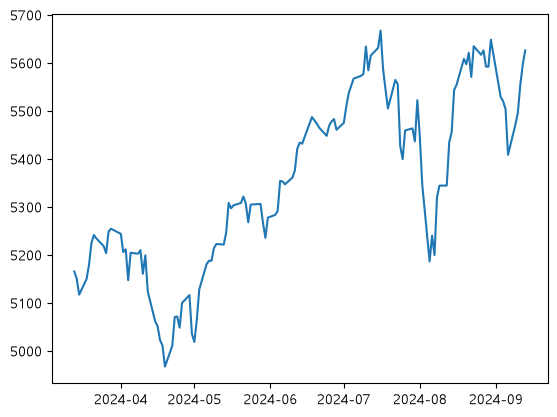

In [31]:
plt.plot(df.index, df.Close)
plt.show()

#### 6.1 pandas.DataFrame.plot()
- https://pandas.pydata.org/pandas-docs/version/0.19.1/generated/pandas.DataFrame.plot.html

*parameters*

- x : label or position, default None
- y : label or position, default None
- kind : str
    - ‘line’ : line plot (default)
    - ‘bar’ : vertical bar plot
    - ‘barh’ : horizontal bar plot
    - ‘hist’ : histogram
    - ‘box’ : boxplot
    - ‘kde’ : Kernel Density Estimation plot
    - ‘density’ : same as ‘kde’
    - ‘area’ : area plot
    - ‘pie’ : pie plot
    - ‘scatter’ : scatter plot
    - ‘hexbin’ : hexbin plot
- figsize : a tuple (width, height) in inches
- title : string
- legend : False/True/’reverse’
- style : list or dict, matplotlib line style per column
- xticks : sequence
- yticks : sequence
- xlim : 2-tuple/list
- ylim : 2-tuple/list

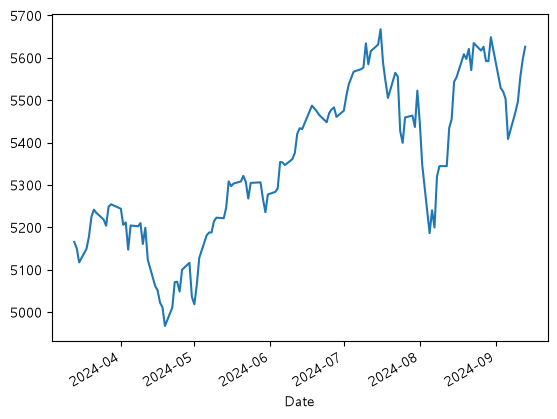

In [32]:
df["Close"].plot()
plt.show()

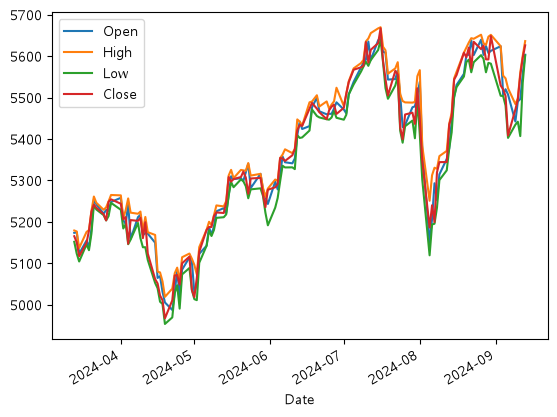

In [33]:
df.plot()
plt.show()

#### 6.2 이동 창(moving window) 함수

df.rolling(): resample()과 유사, 1칸씩 이동하면서 주어진 창 크기만큼 그룹을 생성

```
df.rolling(window,      #계산할 창(window)의 크기
    min_periods=None,   #계산할 최소 크기(기간), 기본적으로 window 크기와 동일
    center=False,       #레이블을 window의 중간에 둘지 여부
    win_type=None,      #가중치를 넣어 계산할 경우 계산 방식
    on=None,            #rolling을 수행할 기준 열
    axis=0,             #계산의 기준이 될 축
    closed=None,        #창 시작과 끝의 포함 여부
    method='single')    #테이블 계산 방식
```

#### 이동평균을 사용하는 이유

이동평균(Moving Average)은 금융 시장에서 가격 데이터의 변동성을 줄이고, 장기적인 추세를 파악하기 위해 주로 사용되는 기술적 분석 도구다. <br>
이동평균을 사용하는 주된 이유는 다음과 같다:

1. **노이즈 감소**: 가격 데이터는 일일 변동성과 단기적인 노이즈가 많기 때문에, 이를 그대로 해석하는 것이 어려울 수 있다. 
 <br>이동평균은 일정 기간 동안의 평균을 계산하여 단기적인 가격 변동의 노이즈를 줄여주고, 더 명확한 추세를 파악할 수 있게 한다.

2. **추세 파악**: 이동평균은 장기적인 가격 움직임을 부드럽게 표현해주기 때문에 상승 또는 하락 추세를 더 쉽게 확인할 수 있다.  <br>
가격이 이동평균 위에 있을 때는 상승 추세로, 아래에 있을 때는 하락 추세로 해석하는 경우가 많다.

3. **지지 및 저항 수준 확인**: 이동평균선은 가격이 멈추거나 반전될 수 있는 잠재적인 지지(하방 지지) 또는 저항(상방 저항) 구간을 제공한다.  <br>
트레이더들은 이를 바탕으로 매수나 매도 시점을 결정하는 데 도움을 받는다.

4. **매매 신호 생성**: 다양한 기간의 이동평균을 함께 사용하여 매매 신호를 생성할 수 있다.  <br>
예를 들어, 단기 이동평균이 장기 이동평균을 상향 돌파할 때는 매수 신호로, 반대로 하향 돌파할 때는 매도 신호로 해석하는 골든크로스와 데드크로스 전략이 있다.

5. **시장 모멘텀 측정**: 이동평균의 기울기를 통해 시장의 모멘텀을 측정할 수 있다.  <br>
이동평균이 가파르게 상승하거나 하락하면 강한 추세를 의미하며, 평평해지면 추세가 약해졌음을 나타낸다.

이동평균은 단순하면서도 강력한 도구로, 주식, 상품, 외환 등 다양한 금융 시장에서 널리 사용된다.  <br>
이를 통해 투자자들은 가격 움직임의 전반적인 흐름을 이해하고, 더 나은 투자 결정을 내릴 수 있다.

**이동 평균 예제**
- rolling(), mean()을 결합

In [34]:
df["Close"].rolling(10).mean().head(20)

Date
2024-03-13         NaN
2024-03-14         NaN
2024-03-15         NaN
2024-03-18         NaN
2024-03-19         NaN
2024-03-20         NaN
2024-03-21         NaN
2024-03-22         NaN
2024-03-25         NaN
2024-03-26    5188.291
2024-03-27    5196.609
2024-03-28    5206.996
2024-04-01    5219.664
2024-04-02    5225.303
2024-04-03    5228.601
2024-04-04    5220.860
2024-04-05    5217.141
2024-04-08    5213.962
2024-04-09    5213.134
2024-04-10    5208.840
Name: Close, dtype: float64

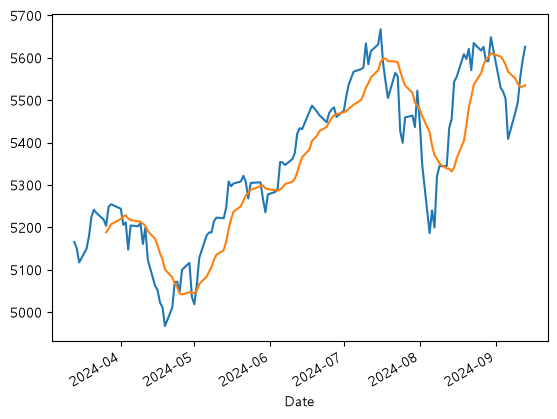

In [35]:
df["Close"].plot()
df["Close"].rolling(10).mean().plot()
plt.show()

#### 6.3 지수 가중 함수
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.ewm.html
- 균등한 가중치를 사용하는 대신, decay factor를 이용해 최근 값에 더 많은 가중치를 주는 방식
- 단순 이동평균에 비해 변화를 더 빠르게 반영하는 특징이 있음

$y_t = \frac{x_t + (1 - \alpha)x_{t-1} + (1 - \alpha)^2 x_{t-2} + ... + (1 -
\alpha)^t x_0}{1 + (1 - \alpha) + (1 - \alpha)^2 + ... + (1 - \alpha)^t}$

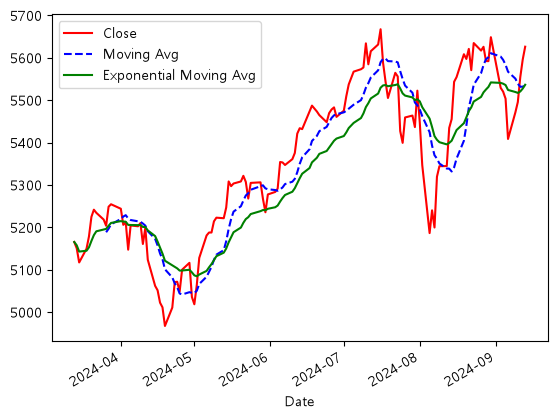

In [36]:
df["Close"].plot(style='r-', label='Close')
df["Close"].rolling(10).mean().plot(style='b--', label='Moving Avg')
df["Close"].ewm(10).mean().plot(style='g-', label='Exponential Moving Avg')
plt.legend()
plt.show()